In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
df = pd.read_csv('Customer_Churn.csv')
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


Observation:

1. Column naming is not uniform i.e we have Upper camel case naming (SeniorCitizen) and lower  case naming (tenure) and many more.

2. Column entries are also not standard, we have a mixture of Upper case (customerID column), spaces (PaymentMethod column), and many more.

To solve we need to:

    replace the spaces with '_'
    apply lower case to both the column naming and the entries

### Data Preparation

a. column naming

In [ ]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.head(10).T

b. column entries

In [12]:
categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for col in categorical_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_').str.replace('-', '_')

In [13]:
df.head().T

,0,1,2,3,4
customerid,7590_vhveg,5575_gnvde,3668_qpybk,7795_cfocw,9237_hqitu
gender,female,male,male,male,female
seniorcitizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phoneservice,no,yes,yes,no,yes
multiplelines,no_phone_service,no,no,no_phone_service,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic
onlinesecurity,no,yes,yes,yes,no


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerid        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   seniorcitizen     7043 non-null   int64  
 3   partner           7043 non-null   object 
 4   dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   phoneservice      7043 non-null   object 
 7   multiplelines     7043 non-null   object 
 8   internetservice   7043 non-null   object 
 9   onlinesecurity    7043 non-null   object 
 10  onlinebackup      7043 non-null   object 
 11  deviceprotection  7043 non-null   object 
 12  techsupport       7043 non-null   object 
 13  streamingtv       7043 non-null   object 
 14  streamingmovies   7043 non-null   object 
 15  contract          7043 non-null   object 
 16  paperlessbilling  7043 non-null   object 


c. fixing the totalcharges column to numeric

In [15]:
tc = pd.to_numeric(df.totalcharges, errors='coerce')

checking if there are any null created after the conversion

In [17]:
tc.isnull().sum()

np.int64(11)

Inspect where the 11 nulls comes from.

In [19]:
df[tc.isnull()][['customerid', 'contract', 'monthlycharges','totalcharges', 'tenure']]

,customerid,contract,monthlycharges,totalcharges,tenure
488,4472_lvygi,two_year,52.55,_,0
753,3115_czmzd,two_year,20.25,_,0
936,5709_lvoeq,two_year,80.85,_,0
1082,4367_nuyao,two_year,25.75,_,0
1340,1371_dwpaz,two_year,56.05,_,0
3331,7644_omvmy,two_year,19.85,_,0
3826,3213_vvolg,two_year,25.35,_,0
4380,2520_sgtta,two_year,20.00,_,0
5218,2923_arzlg,one_year,19.70,_,0
6670,4075_wkniu,two_year,73.35,_,0


Observation:

these are new customers so the billing has not been rolled out yet. So we fill the missing values with 0.

In [21]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')

df.totalcharges = df.totalcharges.fillna(0)

d. Encoding the target variable

In [23]:
df.churn.unique()

array(['no', 'yes'], dtype=object)

In [24]:
df.churn = (df.churn == 'yes').astype(int)

In [25]:
df.churn.unique()

array([0, 1])

## 2. Splitting the Data

In [26]:
from sklearn.model_selection import train_test_split

split the data into 60/20/20, 60% train data, 20% validation, 20% test data

1st split 80% train, 20% test
then we again split the 80% which will be our 100% to 75% and 25% inorder for the test and the validation data to be the same.

In [ ]:
df_full_train, df_test = train_test_split(df, test_size=0.20, random_state=42)

In [28]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

Resetting the index.

In [29]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

#Isolating the target variable from the features
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

# removing the target variable from the dataframe
del df_train['churn']
del df_val['churn']
del df_test['churn']

## 3. EDA (Exploratory Data Analysis)

Check for missing values

look at the distribution of the target variables

Go through the numerical and categorical columns

for EDA we use the full train set because we will use it to compute feature importance

In [32]:
df_full_train = df_full_train.reset_index(drop=True)


check for missing values

In [ ]:
df_full_train.isnull().sum()

Observation:

No nulls

looking at the distribution of the target variables

In [35]:
df_full_train.churn.value_counts(normalize=True)

churn
0    0.734469
1    0.265531
Name: proportion, dtype: float64

churn rate is approximately 27%

In [42]:
categorical = [
    col
    for col in df_full_train.dtypes[df_full_train.dtypes == 'object'].index
    if col != 'customerid'
]

categorical.append('seniorcitizen')


In [41]:
numerical_cols = ['tenure', 'monthlycharges', 'totalcharges']

number of categories per column in the categorical columns

In [45]:
df_full_train[categorical].nunique().sort_values(ascending=False)

paymentmethod       4
onlinebackup        3
internetservice     3
onlinesecurity      3
techsupport         3
streamingtv         3
deviceprotection    3
multiplelines       3
streamingmovies     3
contract            3
dependents          2
phoneservice        2
gender              2
partner             2
paperlessbilling    2
seniorcitizen       2
dtype: int64

## Feature Importance: Churn Rate and Risk ratio

Churn rate per group

In [46]:
globalChurn_mean = df_full_train.churn.mean()
globalChurn_mean

np.float64(0.2655307064252751)

let's start with gender

In [47]:
df_full_train.groupby('gender').churn.mean()

gender
female    0.270841
male      0.260478
Name: churn, dtype: float64

27% of female customers churned

26% of make customers churned

### Calculating the difference

In [48]:
# females
0.270841 - 0.2655307064252751

0.0053102935747249

In [49]:
# males
0.260478 - 0.2655307064252751

-0.005052706425275111

Does belonging to this category change the probability of churn compared to the average customer?

For the gender category belonging to the male or female category does not change the probability of churn.

partner category

In [54]:
df_full_train.groupby('partner').churn.mean()

partner
no     0.326446
yes    0.200733
Name: churn, dtype: float64

Observation:

customers with no partners churn at 32.6% while customers with partners churn at 20.1%

In [55]:
# No partner
0.326446 - 0.2655307064252751

0.060915293574724916

In [56]:
# with partner
0.200733 - 0.2655307064252751

-0.0647977064252751

Customers with partners churn 6 percentage points less than the average customers.

Customers without partners churn 6 percentage points more than the average customers.

This suggests that partner is associated with churn.

### Risk ratio

Risk = group / global

if risk = 1 = the group ia as likely to churn as everyone else

if risk > 1 = more likely to churn

if risk < 1 = less likely to churn

In [58]:
churn_partner = df_full_train[df_full_train.partner == 'yes'].churn.mean()
churn_no_partner = df_full_train[df_full_train.partner == 'no'].churn.mean()

print(churn_partner, churn_no_partner)

0.20073260073260074 0.32644628099173556


In [59]:
churn_no_partner / globalChurn_mean

np.float64(1.2294106598311754)

In [60]:
churn_partner / globalChurn_mean

np.float64(0.7559675618499149)

Customers without a partner have 1.23 times the average churn risk hence more likely to churn.

Customers with a partner have 0.76 times the average churn risk, less likely to churn.

Calculating risk ratio for every feature

In [62]:
from IPython.display import display

for c in categorical:
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - globalChurn_mean
    df_group['risk'] = df_group['mean'] / globalChurn_mean
    display(df_group) 
    print()
    print()

,mean,count,diff,risk
gender,,,,
female,0.270841,2747,0.005310,1.019998
male,0.260478,2887,-0.005053,0.980971


,mean,count,diff,risk
partner,,,,
no,0.326446,2904,0.060916,1.229411
yes,0.200733,2730,-0.064798,0.755968


,mean,count,diff,risk
dependents,,,,
no,0.312326,3951,0.046795,1.176233
yes,0.155674,1683,-0.109856,0.586276


,mean,count,diff,risk
phoneservice,,,,
no,0.253623,552,-0.011908,0.955156
yes,0.266824,5082,0.001293,1.004871


,mean,count,diff,risk
multiplelines,,,,
no,0.251397,2685,-0.014134,0.946771
no_phone_service,0.253623,552,-0.011908,0.955156
yes,0.284105,2397,0.018574,1.069952


,mean,count,diff,risk
internetservice,,,,
dsl,0.191851,1939,-0.073679,0.722521
fiber_optic,0.415558,2481,0.150028,1.565010
no,0.076606,1214,-0.188924,0.288502


... (6 outputs left out)

,mean,count,diff,risk
contract,,,,
month_to_month,0.426533,3083,0.161002,1.606340
one_year,0.117987,1212,-0.147544,0.444343
two_year,0.028379,1339,-0.237151,0.106878


,mean,count,diff,risk
paperlessbilling,,,,
no,0.16414,2309,-0.101390,0.618159
yes,0.33594,3325,0.070409,1.265164


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.174475,1238,-0.091056,0.657080
credit_card_(automatic),0.152404,1227,-0.113126,0.573961
electronic_check,0.449921,1887,0.184390,1.694420
mailed_check,0.190328,1282,-0.075203,0.716782


,mean,count,diff,risk
seniorcitizen,,,,
0,0.237098,4728,-0.028433,0.892922
1,0.413907,906,0.148377,1.558793


For every categorical variable we take the mean of churn for each group - the group churn rate- and the number of rows in the group.Then we add two columns: diff and risk. Note that a positive diff means the group churns more than average. The risk column is the ratio between the group mean and the the global mean of churn.

We use the display function from IPython to print a table.

## Mutual Information

Mutual information measures the importance of categorical variables.

In [65]:
from sklearn.metrics import mutual_info_score

In [66]:
mutual_info_score(df_full_train.churn, df_full_train.contract)

0.0966515250997

In [67]:
mutual_info_score(df_full_train.gender, df_full_train.churn)

6.877785208564413e-05

In [69]:
mutual_info_score(df_full_train.churn, df_full_train.partner)

0.010227084558171867

## Apply it to all categorical variables

In [70]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

In [72]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.096652
onlinesecurity      0.063393
techsupport         0.060935
internetservice     0.053313
onlinebackup        0.045424
paymentmethod       0.042861
deviceprotection    0.042007
streamingtv         0.030844
streamingmovies     0.030705
paperlessbilling    0.019077
dependents          0.014129
partner             0.010227
seniorcitizen       0.010059
multiplelines       0.000654
gender              0.000069
phoneservice        0.000040
dtype: float64

<Axes: >

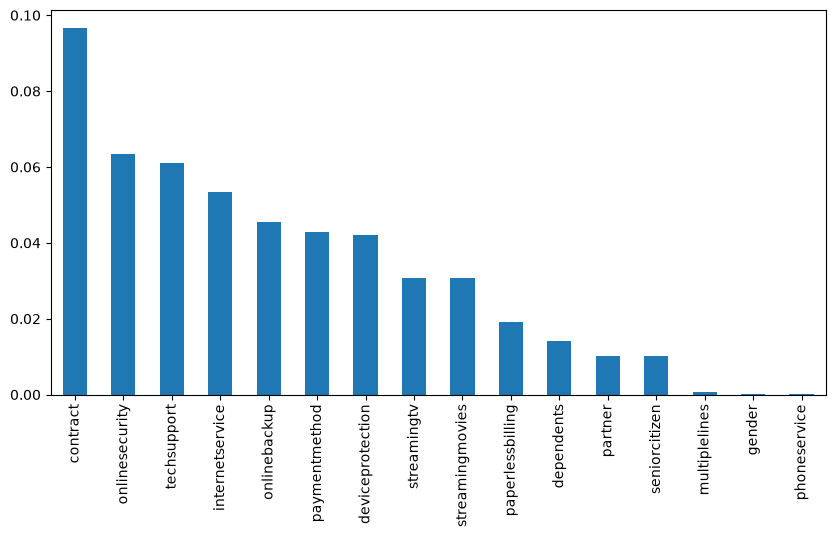

In [71]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False).plot(kind='bar', figsize=(10, 5))

The result puts everything on one scale. Contract is most important categorical variable, followed by onlinesecurity and techsupport - customers without these services tend to churn more, as shown in the risk ratio tables. At the bottom of the list we find multiplelines, phoneservice and gender - variables that tell us almost nothing about churn.

## Pearson Correlation

For numerical variables, we use the correlation coefficient insted: it tells us how strongly each numerical feature is related to churn.

The Pearson correlation coefficient always a number betwen -1 and 1:

- A value close to 1 means strong positive correlation: when one variable grows, the other grows too.

- A value close to -1 means a strong negative correlation: when one variable grows, the other one decreases.

- A value close to 0 means there is no dependency: a change in one variable tells us nothing about the other.

The sign gives us the direction of the relationship, and the absolute value gives it's strength. One way to interpret the magnitude:

- LOW when the absolute value of r is between 0 and 0.2

- MEDIUM when it is between 0.2 and 0.5

- STRONG when it is between 0.5 and 1.0

### Correlation of numerical features with churn

In [76]:
df_full_train[numerical_cols].corrwith(df_full_train.churn)

tenure           -0.344925
monthlycharges    0.188574
totalcharges     -0.193370
dtype: float64

<Axes: title={'center': 'Correlation with Churn'}>

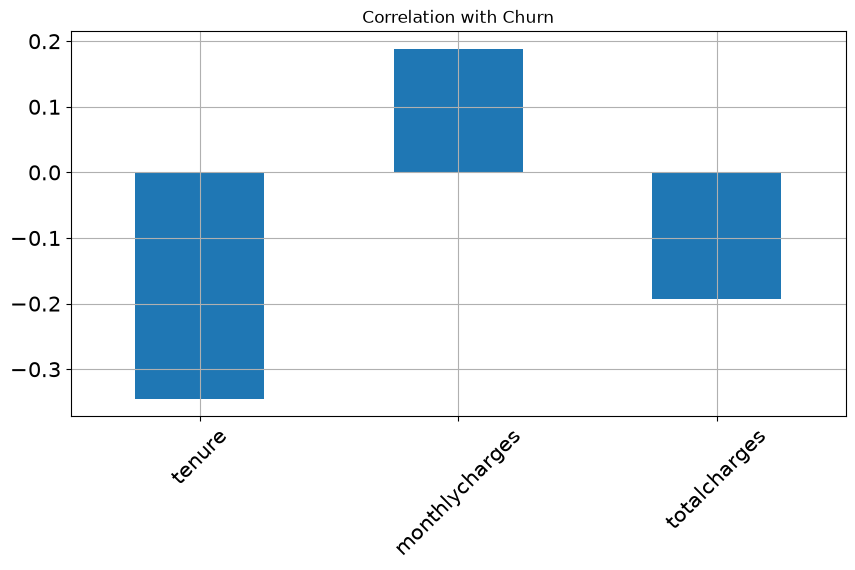

In [75]:
df_full_train[numerical_cols].corrwith(df_full_train.churn).plot.bar(figsize=(10, 5), title="Correlation with Churn", fontsize=15, rot=45, grid=True)

Observation:

- Tenure has a medium negative correlation. The longer customers stay with he company, the less likely they are to churn.

- Monthly charges have low-to-medium positive correlation: the more customers pay per month, the more likely they are to churn.

- Total charges have a low-to-medium correlation - not surprising, since total charges accumulatewith tenure.

correlation absolute

In [77]:
df_full_train[numerical_cols].corrwith(df_full_train.churn).abs()

tenure            0.344925
monthlycharges    0.188574
totalcharges      0.193370
dtype: float64

### Checking the relationship with groups

Double checking the correlation by splitting customers into groups and computing churn rate in each group. Applying the same idea in categorical variables but now in numerical variable grouped into bins.

In [78]:
df_full_train.tenure.max()

72

split it into three groups - six months or less, up to two years, and longer than two years - and look at the churn rate in each.

In [79]:
df_full_train[df_full_train.tenure <= 6].churn.mean()

np.float64(0.5310344827586206)

In [80]:
df_full_train[(df_full_train.tenure > 6) & (df_full_train.tenure <= 24)].churn.mean()

np.float64(0.3103942652329749)

In [81]:
df_full_train[df_full_train.tenure > 24].churn.mean()

np.float64(0.14517700552127313)

Customers who have been with the company for six months or less churn at almost 53%. For customers of upto two years it is 31%, and for those who stayed longer than two years, only about 18%. Churn clearly decreases as tenure grows.

Checking if the same applies to monthly charges

In [84]:
df_full_train.monthlycharges.max()

118.6

In [85]:
df_full_train[df_full_train.monthlycharges <= 20].churn.mean()

np.float64(0.0912621359223301)

In [86]:
df_full_train[(df_full_train.monthlycharges > 20) & (df_full_train.monthlycharges <= 50)].churn.mean()

np.float64(0.19062027231467474)

In [87]:
df_full_train[df_full_train.monthlycharges >50].churn.mean()

np.float64(0.3152488806952857)

Here the relationship is, when monthly charges increases, the churn rate also increases, the relationship was positive. customers paying at most $20 have a lower rate to churn - 9% churn rate - compared to those customers with monthly charges of more than $50 whose churn rate is 32%

In [90]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [95]:
numerical_cols

['tenure', 'monthlycharges', 'totalcharges']

In [93]:
categorical

['gender',
 'partner',
 'dependents',
 'phoneservice',
 'multiplelines',
 'internetservice',
 'onlinesecurity',
 'onlinebackup',
 'deviceprotection',
 'techsupport',
 'streamingtv',
 'streamingmovies',
 'contract',
 'paperlessbilling',
 'paymentmethod',
 'seniorcitizen']

### Training the model

In [99]:
train_dict = df_train[categorical + numerical_cols].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
dv.fit(train_dict)

X_train = dv.transform(train_dict)

model = LogisticRegression(solver='lbfgs', C=1.0)
model.fit(X_train, y_train)

c:\Users\User\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

We can fix this model by using a scalar and also use `OneHotEncoding` instead of `DictVectorizer`

## Feature scaling + One-hot Encoding

In [88]:
df_full_train.contract.unique()

array(['one_year', 'two_year', 'month_to_month'], dtype=object)

In [89]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler

First, prepare the numerical variables. Use the scaler for that and write the results to `X_train_num`

In [100]:
X_train_num = df_train[numerical_cols].values

scaler = StandardScaler()
#scaler = MinMaxScaler()

X_train_num = scaler.fit_transform(X_train_num)

The scaler scales the numerical features.

In [101]:
df_train.tenure.values

array([ 3, 55, 24, ..., 15, 45, 29])

In [102]:
X_train_num[:, 0]

array([-1.19750587,  0.93910874, -0.33464228, ..., -0.70444096,
        0.52822131, -0.12919857])

Let's process categorical features using `OneHotEncoding` and write the results to `X_train_cat`:

In [106]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

In [107]:
X_train_cat = ohe.fit_transform(df_train[categorical].values)

In [109]:
ohe.get_feature_names_out()

array(['x0_female', 'x0_male', 'x1_no', 'x1_yes', 'x2_no', 'x2_yes',
       'x3_no', 'x3_yes', 'x4_no', 'x4_no_phone_service', 'x4_yes',
       'x5_dsl', 'x5_fiber_optic', 'x5_no', 'x6_no',
       'x6_no_internet_service', 'x6_yes', 'x7_no',
       'x7_no_internet_service', 'x7_yes', 'x8_no',
       'x8_no_internet_service', 'x8_yes', 'x9_no',
       'x9_no_internet_service', 'x9_yes', 'x10_no',
       'x10_no_internet_service', 'x10_yes', 'x11_no',
       'x11_no_internet_service', 'x11_yes', 'x12_month_to_month',
       'x12_one_year', 'x12_two_year', 'x13_no', 'x13_yes',
       'x14_bank_transfer_(automatic)', 'x14_credit_card_(automatic)',
       'x14_electronic_check', 'x14_mailed_check', 'x15_0', 'x15_1'],
      dtype=object)

We combine the two matrices into one - `X_train`

In [110]:
X_train = np.column_stack([X_train_num, X_train_cat])

Then train the model

In [111]:
model = LogisticRegression(solver='lbfgs', C=1.0, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solve

### Validation data

In [113]:
#handling the numeriical columns of the validation data
X_val_num = df_val[numerical_cols].values
X_val_num = scaler.transform(X_val_num)

X_val_cat = ohe.transform(df_val[categorical].values)

X_val = np.column_stack([X_val_num, X_val_cat])

The model has two prediction methods, and the difference matters:

- `model.predict(X)` gives hard predictions - the final 0/1 answer

- `model.predict_proba(x)` gives soft predictions - the actual probabilities

We want the probabilities, because we will apply our own threshold:

In [114]:
y_pred = model.predict_proba(X_val)[:, 1]
accuracy_score(y_val, y_pred >= 0.5)

0.8026969481902059

`predict_proba` returns a matrix with two columns: the probability of class 0 and the probality of class 1. The two columns always sum up to 1, so it is enough to take the second one - hence `[:, 1]`.

Now we decide: if the model thinks the probability of churn is 50% or more, we predict that the customer will churn

The result is a boolean array. We can use it to select the customers the model thinks will churn - for example, the ones who should receive a promotional email with a discount. Selecting the validation rows with this mask gives 311 customers.

### Retrain the model on the Train and Validation set

In [116]:
X_full_train_num = df_full_train[numerical_cols].values
X_full_train_num = scaler.transform(X_full_train_num)

X_full_train_cat = ohe.transform(df_full_train[categorical].values)

X_full_train = np.column_stack([X_full_train_num, X_full_train_cat]) 

y_full_train = df_full_train.churn.values

In [117]:
model = LogisticRegression(solver='lbfgs')
model.fit(X_full_train, y_full_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [118]:
# Handling both numerical and categorical data for test data
X_test_num = df_test[numerical_cols].values
X_test_num = scaler.transform(X_test_num)

X_test_cat = ohe.transform(df_test[categorical].values)

X_test = np.column_stack([X_test_num, X_test_cat])

In [119]:
y_pred = model.predict_proba(X_test)[:, 1]
accuracy_score(y_test, y_pred >= 0.5)

0.8211497515968772

The accuracy on the test set is about 82.11%. On validation it was 80.27%. The two numbers are close, the model performs on unseen data even better than the data it was tuned with. A large gap between the two would be a sign of Overfitting. 

### Scoring one customer

In [122]:
customer = df_test.tail(1)
customer

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges
1408,5868_czjdr,male,0,no,yes,1,no,no_phone_service,dsl,no,yes,no,no,no,no,month_to_month,yes,mailed_check,31.35,31.35


In [123]:
X_small_num = customer[numerical_cols].values
X_small_num = scaler.transform(X_small_num)

X_small_cat = ohe.transform(customer[categorical].values)

X_small = np.column_stack([X_small_num, X_small_cat])

In [129]:
model.predict_proba(X_small)

array([[0.50300885, 0.49699115]])

50% probability customer stays

49.7% probability customer churns

In [128]:
prediction = model.predict(X_small)
prediction

array([0])

In [127]:
y_test[-1]

np.int64(1)